In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler


# 데이터 로드
wine_data = load_wine() # wine 데이터를 wine_data 변수에 대입, wine_data는 딕셔너리 형태
df = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names) # wine data set의 data와 feature_name의 컬럼명으로 DataFrame 생성
df['target'] = wine_data.target # wine의 품종/등급 데이터를 'target'이라는 새 컬럼으로 추가
df['wine_class'] = df['target'].map({0 : 'class_0', 1: 'class_1', 2:'class_2'}) # 타겟을 class 별로 분류 -> 범주형 데이터로 변환
df.drop(columns = ['target'], inplace=True) # 기존 숫자형 target 컬럼 삭제


# load_wine 데이터셋에 결측지/중복값이 있는지 확인하기
print(f"데이터 크기 : {df.shape[0]}행 {df.shape[1]}열")
print(f"결측치 총 개수: {df.isnull().sum().sum()}개")   # 결측치가 0개임
print(f"중복 행 총 개수: {df.duplicated().sum()}개")     # 중복 데이터가 0개임

display(df)

데이터 크기 : 178행 14열
결측치 총 개수: 0개
중복 행 총 개수: 0개


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,class_2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,class_2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,class_2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,class_2


In [18]:
# display(df)를 통해 wine dataset은 13개 특성이 모두 실수형 데이터임을 확인

# 변수 간 스케일 격차 및 분포도 확인
numeric = wine_data.feature_names # 타겟을 제외한 순수 13개(alcohol, malic_acid, ..., wine_class) 화학 성분 컬럼명 리스트
scale_check = pd.DataFrame({
    'Min': df[numeric].min(),             # 최솟값
    'Max': df[numeric].max(),             # 최댓값
    'Mean': df[numeric].mean(),           # 평균
    'Std': df[numeric].std(),             # 표준편차
    'Skewness': df[numeric].skew()  # 0에서 멀수록(보통 ±1 이상) 분포가 한쪽으로 쏠려있음
})

display(scale_check)

,Min,Max,Mean,Std,Skewness
alcohol,11.03,14.83,13.000618,0.811827,-0.051482
malic_acid,0.74,5.80,2.336348,1.117146,1.039651
ash,1.36,3.23,2.366517,0.274344,-0.176699
alcalinity_of_ash,10.60,30.00,19.494944,3.339564,0.213047
magnesium,70.00,162.00,99.741573,14.282484,1.098191
total_phenols,0.98,3.88,2.295112,0.625851,0.086639
flavanoids,0.34,5.08,2.029270,0.998859,0.025344
nonflavanoid_phenols,0.13,0.66,0.361854,0.124453,0.450151
proanthocyanins,0.41,3.58,1.590899,0.572359,0.517137
color_intensity,1.28,13.00,5.058090,2.318286,0.868585


In [19]:
scaler = StandardScaler()# 서로 다른 단위를 가진 변수들을 또같은 기준선 위로 맞추기
scaled_df=pd.DataFrame(scaler.fit_transform(df[numeric]), columns=numeric)

# 시각화하기 1
plt.figure(figsize=(30, 120)) # 그래프 공간 생성, 30=x축, 120=y축
sns.boxplot(data=scaled_df, orient='horizontal') # 표준화 시킨 scaled_df 데이터프레임 사용 , h는 변수명
plt.title('Standardized Boxplot of 13 Features') # 그레프 이름
plt.xlabel('Standardized Value') # X축 이름
plt.tight_layout() # 여백 자동 조정
plt.show()


Output hidden; open in https://colab.research.google.com to view.

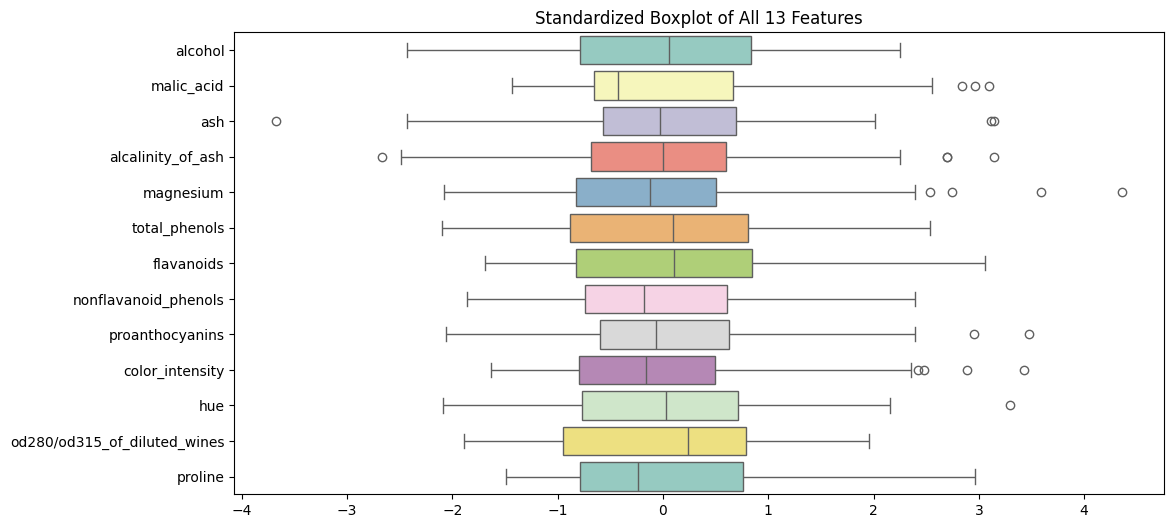

In [22]:
# 세로로 길어지는 문제 해결하기
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric].apply(lambda x: (x - x.mean()) / x.std()), orient='h', palette='Set3')
plt.title('Standardized Boxplot of All 13 Features')
plt.show()

/tmp/ipykernel_593/3269030284.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_593/3269030284.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


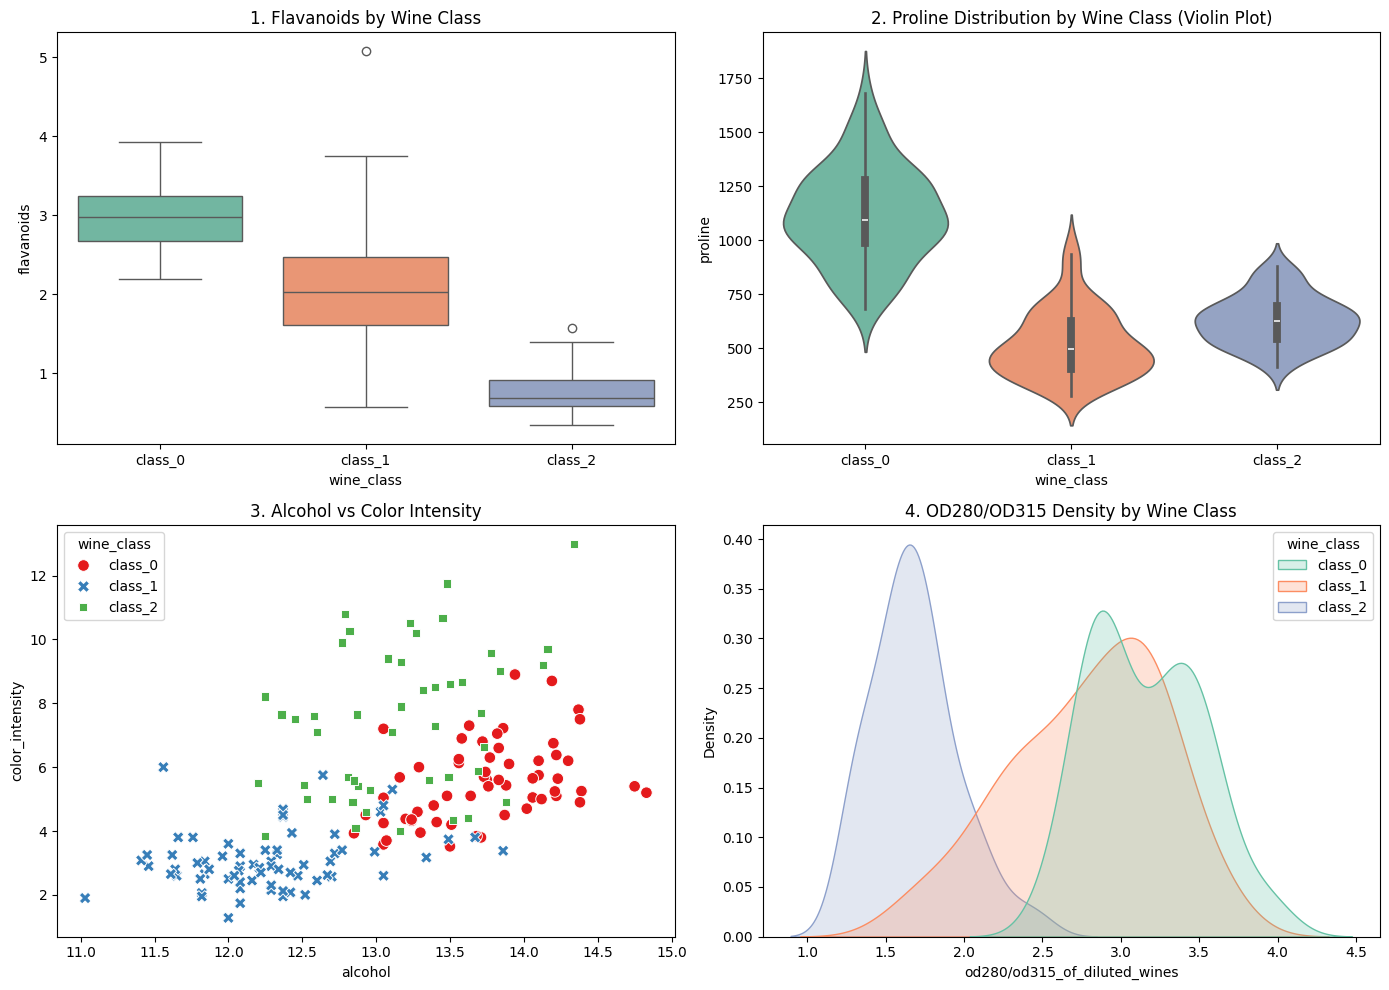

In [20]:
# 시각화 2
# wine_data와 상관관계가 가장 높은 핵심 변수 4개의 분포 비교
# 2행 2열(총 4칸)의 격자 구조를 만들고, 전체 도화지(fig) 크기는 가로 14, 세로 10인치로 설정 (axes는 각 칸의 위치 배열)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Flavanoids (플라보노이드): 와인 품종을 가르는 가장 강력한 변수 중 하나
sns.boxplot(
    data=df,                 # 원본 데이터프레임 사용
    x='wine_class',          # X축: 와인 품종 범주 (Class_0, Class_1, Class_2)
    y='flavanoids',          # Y축: 플라보노이드 수치 (사분위수, 중앙값, 이상치를 박스 형태로 표시)
    ax=axes[0, 0],           # 2x2 격자 중 첫 번째 칸(0행 0열, 왼쪽 위)에 그래프 배치
    palette='Set2'           # 부드러운 색상 팔레트(Set2) 적용
)
axes[0, 0].set_title('1. Flavanoids by Wine Class')  # 첫 번째 칸의 소제목 설정

# 2) Proline (프롤린 아미노산): Class_0이 압도적으로 높은 수치를 보임
sns.violinplot(
    data=df,                 # 원본 데이터프레임 사용
    x='wine_class',          # X축: 와인 품종 범주
    y='proline',             # Y축: 프롤린 아미노산 함량 (박스플롯 + 데이터 밀도 분포를 바이올린 모양으로 동시 표현)
    ax=axes[0, 1],           # 2x2 격자 중 두 번째 칸(0행 1열, 오른쪽 위)에 그래프 배치
    palette='Set2'           # 색상 팔레트(Set2) 적용
)
axes[0, 1].set_title('2. Proline Distribution by Wine Class (Violin Plot)')  # 두 번째 칸의 소제목 설정

# 3) Alcohol (알코올 도수) vs Color Intensity (색의 강도) 산점도
sns.scatterplot(
    data=df,                 # 원본 데이터프레임 사용
    x='alcohol',             # X축: 알코올 도수
    y='color_intensity',     # Y축: 색의 강도 (두 연속형 변수 간의 관계 및 군집 형성 여부 확인)
    hue='wine_class',        # 와인 품종별로 점의 색상을 다르게 구분
    style='wine_class',      # 와인 품종별로 점의 모양(동그라미, 엑스, 네모 등)도 다르게 구분해 가독성 향상
    s=70,                    # 점의 크기(size)를 70으로 설정하여 잘 보이게 조절
    ax=axes[1, 0],           # 2x2 격자 중 세 번째 칸(1행 0열, 왼쪽 아래)에 그래프 배치
    palette='Set1'           # 대비가 뚜렷한 원색 계열 팔레트(Set1) 적용
)
axes[1, 0].set_title('3. Alcohol vs Color Intensity')  # 세 번째 칸의 소제목 설정

# 4) OD280/OD315 (단백질 함량 지표) 밀도 곡선(KDE)
sns.kdeplot(
    data=df,                                 # 원본 데이터프레임 사용
    x='od280/od315_of_diluted_wines',        # X축: 희석된 와인의 흡광도 비율(단백질 함량 지표)
    hue='wine_class',                        # 와인 품종별로 밀도 곡선 색상을 다르게 구분
    fill=True,                               # 곡선 아래 영역을 반투명 색상으로 채워 겹치는 구간을 직관적으로 비교
    ax=axes[1, 1],                           # 2x2 격자 중 네 번째 칸(1행 1열, 오른쪽 아래)에 그래프 배치
    palette='Set2'                           # 색상 팔레트(Set2) 적용
)
axes[1, 1].set_title('4. OD280/OD315 Density by Wine Class')  # 네 번째 칸의 소제목 설정

plt.tight_layout()
plt.show()

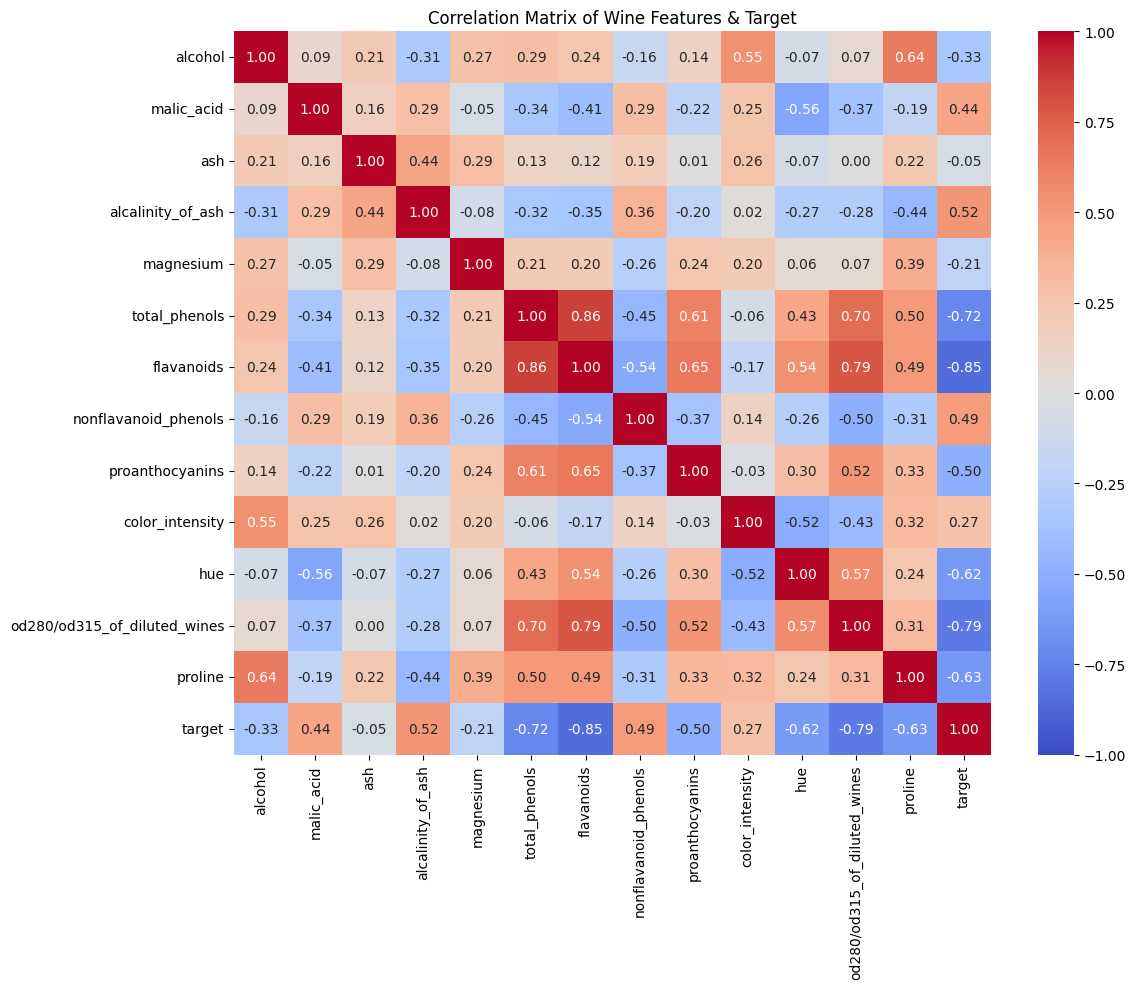

In [21]:
# 시각화 3 전체 변수 간 상관계수 히트맵 (다중공선성 및 주요 특성 파악)
plt.figure(figsize=(12, 10))  # 14x14 칸의 큰 표가 빽빽하지 않도록 가로 12, 세로 10인치 도화지 생성
corr_matrix = df[numeric + ['target']].corr()  # 13개 화학 성분 변수와 정답(target)을 합친 총 14개 열의 피어슨 상관계수(-1~1) 계산
sns.heatmap(
    corr_matrix,             # 계산된 상관계수 행렬(표) 데이터 입력
    annot=True,              # True: 각 네모 칸 안에 정확한 상관계수 숫자를 글씨로 표시
    fmt='.2f',               # 숫자를 소수점 둘째 자리까지만 깔끔하게 반올림하여 표시 (예: 0.86)
    cmap='coolwarm',         # 양의 상관관계(+)는 따뜻한 빨간색, 음의 상관관계(-)는 차가운 파란색으로 표현
    vmin=-1,                 # 색상 막대의 최솟값을 -1로 고정 (완전한 음의 상관관계 기준)
    vmax=1                   # 색상 막대의 최댓값을 +1로 고정 (완전한 양의 상관관계 기준)
)
plt.title('Correlation Matrix of Wine Features & Target')  # 히트맵 상단 제목 설정
plt.tight_layout()  # 변수명이 길어서 아래쪽이나 왼쪽이 잘리는 현상을 막기 위해 여백 자동 조정
plt.show()